In [ ]:
!pip install -q osmnx==2.1.0 scipy>=1.13 networkx>=3.0 shapely>=2.0 numpy>=2.0 pandas>=2.0

In [ ]:
!unzip -q sangli_pilot_package.zip


BALANCED
Population: 2,822,143
Constituency 1: 352,697 people → 236 booths
Constituency 2: 359,880 people → 240 booths
Constituency 3: 350,756 people → 234 booths
Constituency 4: 355,894 people → 238 booths
Constituency 5: 344,129 people → 230 booths
Constituency 6: 352,617 people → 236 booths
Constituency 7: 353,341 people → 236 booths
Constituency 8: 352,829 people → 236 booths

Total booths: 1,886
EVM transport distance: 23,923.25 km
Voter travel: 844,572.78 person-km
Average voter distance: 0.30 km

LOCALITY
Population: 2,822,143
Constituency 1: 369,031 people → 247 booths
Constituency 2: 346,121 people → 231 booths
Constituency 3: 362,092 people → 242 booths
Constituency 4: 345,525 people → 231 booths
Constituency 5: 350,392 people → 234 booths
Constituency 6: 352,213 people → 235 booths
Constituency 7: 349,604 people → 234 booths
Constituency 8: 347,165 people → 232 booths

Total booths: 1,886
EVM transport distance: 23,775.57 km
Voter travel: 876,203.99 person-km
Average voter 

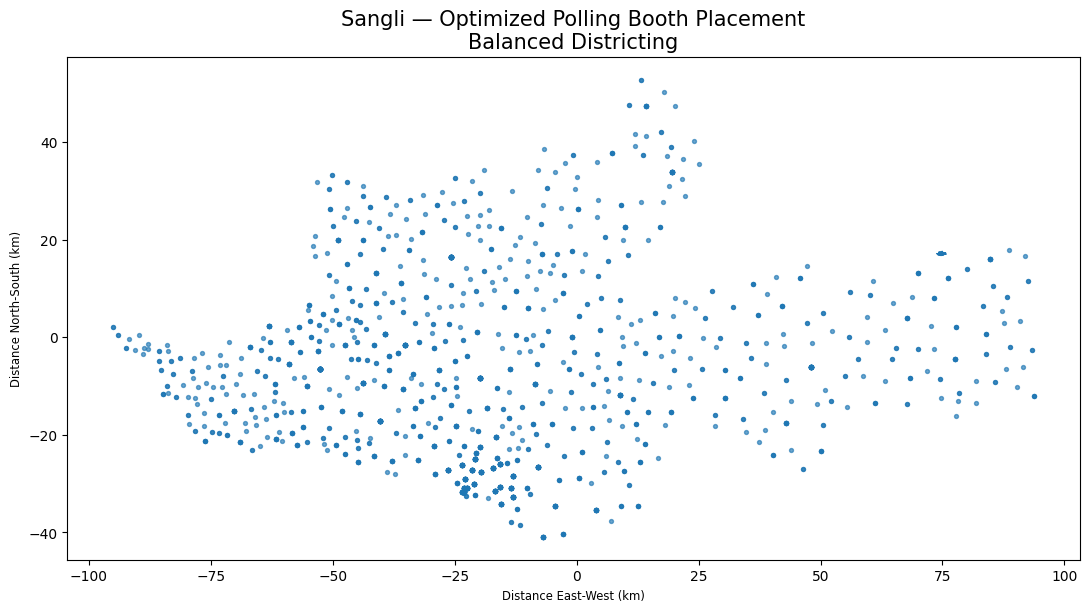

Saved: logistics_euclidean/booth_placement_balanced.png


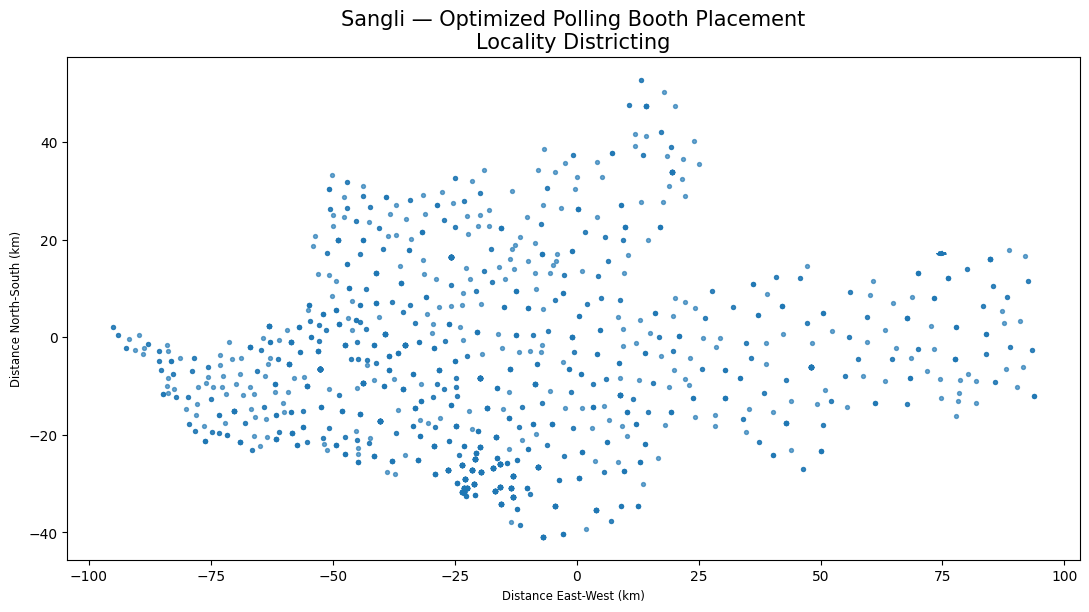

Saved: logistics_euclidean/booth_placement_locality.png


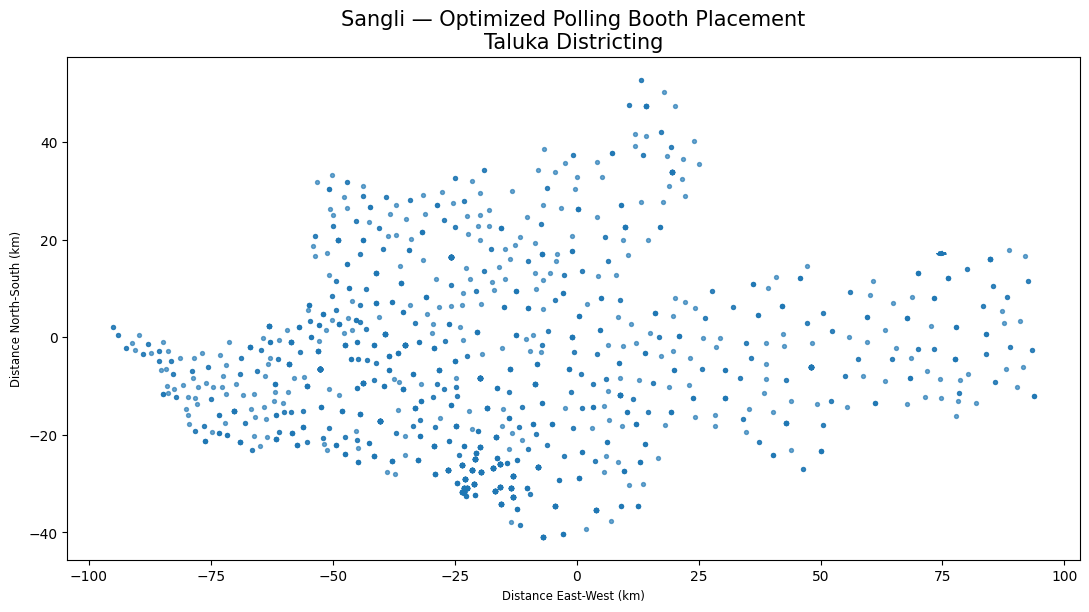

Saved: logistics_euclidean/booth_placement_taluka.png


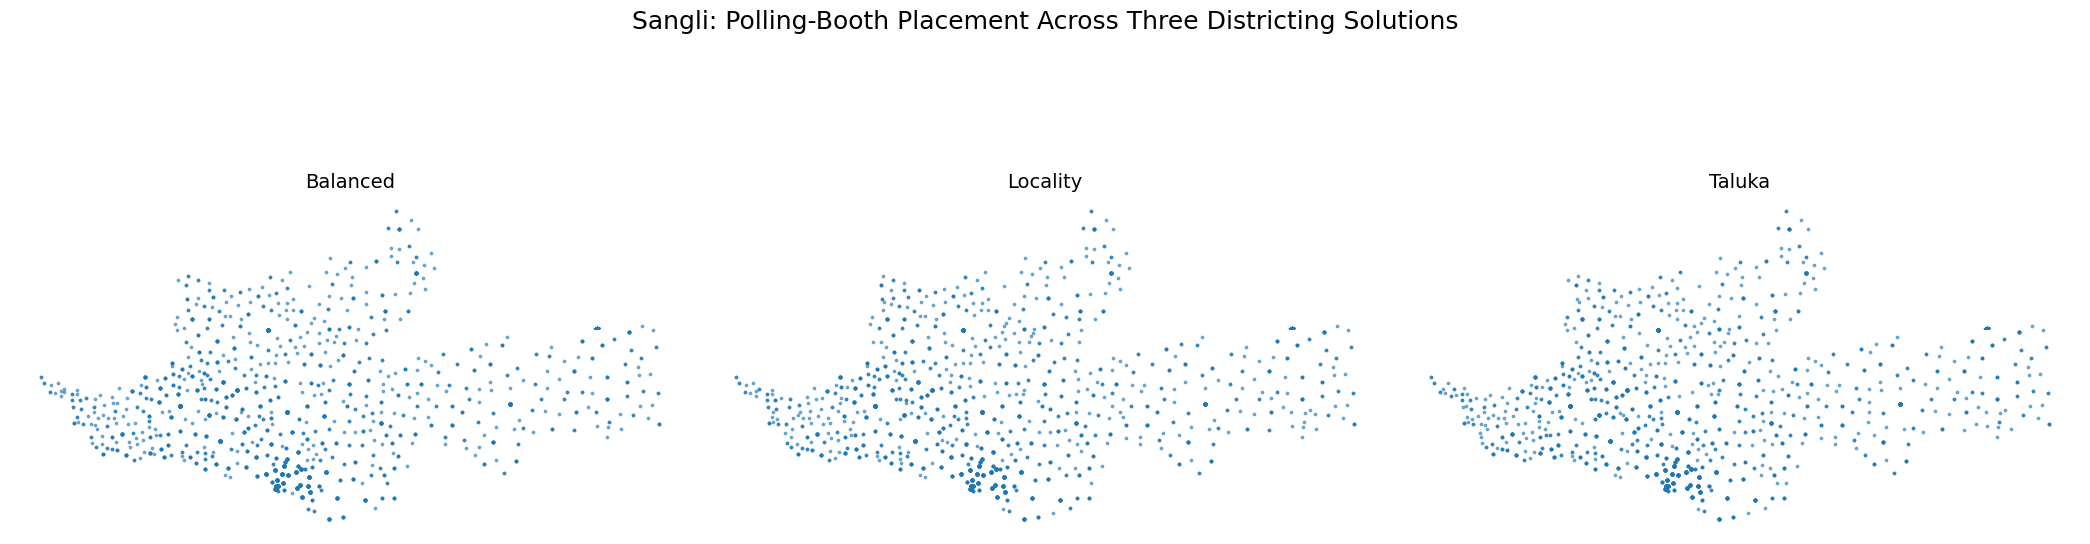



FINAL COMPARISON


,Map,Population,Booths,EVM transport km,Voter person-km,Average voter distance km
0,Balanced,2822143,1886,23923.25,844572.78,0.299
1,Locality,2822143,1886,23775.57,876203.99,0.310
2,Taluka,2822143,1885,23781.90,945532.06,0.335



Combined map saved at: logistics_euclidean/booth_placement_comparison.png


In [ ]:
# ================================================================
# SANGli ELECTION LOGISTICS — EUCLIDEAN BOOTH PLACEMENT
# ================================================================
#
# INPUT:
#   map_balanced/assigned_units.geojson
#   map_locality/assigned_units.geojson
#   map_taluka/assigned_units.geojson
#   sangli_input/sangli_district.geojson
#
# OUTPUT:
#   logistics_euclidean/
#       booth_placement_balanced.png
#       booth_placement_locality.png
#       booth_placement_taluka.png
#       booth_placement_comparison.png
#       logistics_comparison.csv
#
# Each booth has maximum 1500 people.
# Booth locations are decision variables chosen from population
# demand locations.
# Distance = straight-line Euclidean distance.
# ================================================================

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from math import ceil, cos, radians


# ================================================================
# SETTINGS
# ================================================================

MAX_PEOPLE_PER_BOOTH = 1500

# Number of improvement iterations
ITERATIONS = 15

# Output folder
OUT = Path("logistics_euclidean")
OUT.mkdir(exist_ok=True)


# ================================================================
# DISTANCE CONVERSION
# ================================================================
# Convert longitude/latitude into approximate kilometres.
# This is much better than directly calculating Euclidean distance
# between raw latitude/longitude values.
# ================================================================

def lonlat_to_km(lon, lat, lon0, lat0):
    """
    Approximate local Cartesian coordinates in kilometres.
    Suitable for a district-sized study area such as Sangli.
    """

    x = (lon - lon0) * 111.32 * cos(radians(lat0))
    y = (lat - lat0) * 110.57

    return x, y


# ================================================================
# LOAD DATA
# ================================================================

district = gpd.read_file(
    "sangli_input/sangli_district.geojson"
)

MAP_FILES = {
    "Balanced": "map_balanced/assigned_units.geojson",
    "Locality": "map_locality/assigned_units.geojson",
    "Taluka": "map_taluka/assigned_units.geojson",
}


# Use district centre as coordinate reference
district_centroid = district.geometry.iloc[0].centroid

LON0 = district_centroid.x
LAT0 = district_centroid.y


# ================================================================
# EUCLIDEAN DISTANCE MATRIX
# ================================================================

def distance_matrix(points_a, points_b):
    """
    Euclidean distance matrix in kilometres.
    """

    A = np.asarray(points_a)
    B = np.asarray(points_b)

    dx = A[:, None, 0] - B[None, :, 0]
    dy = A[:, None, 1] - B[None, :, 1]

    return np.sqrt(dx**2 + dy**2)


# ================================================================
# INITIAL BOOTH LOCATION SELECTION
# ================================================================

def initial_booth_sites(points, population, n_booths):
    """
    Select candidate booth locations.

    Booth locations are spread spatially using a weighted
    farthest-first procedure.

    High-population locations are given greater importance.
    """

    n = len(points)

    if n_booths <= n:

        # First location: highest population point
        selected = [int(np.argmax(population))]

        while len(selected) < n_booths:

            D = distance_matrix(points, points[selected])

            # Distance to closest already-selected site
            nearest_distance = D.min(axis=1)

            # Give populated/far-away points more priority
            score = nearest_distance * np.sqrt(
                population / population.max()
            )

            score[selected] = -1

            selected.append(int(np.argmax(score)))

        return np.array(selected)

    else:

        # More booths than population units.
        # Allocate multiple booths to high-population sites.

        weights = population / population.sum()

        raw = weights * n_booths

        counts = np.floor(raw).astype(int)

        # Make sure every site with meaningful population can
        # potentially receive at least one booth.
        counts = np.maximum(counts, 0)

        remaining = n_booths - counts.sum()

        if remaining > 0:

            fractional = raw - np.floor(raw)

            order = np.argsort(-fractional)

            for i in order[:remaining]:
                counts[i] += 1

        elif remaining < 0:

            fractional = raw - np.floor(raw)

            order = np.argsort(fractional)

            for i in order:

                if remaining == 0:
                    break

                if counts[i] > 0:
                    counts[i] -= 1
                    remaining += 1

        sites = []

        for i, count in enumerate(counts):
            sites.extend([i] * int(count))

        return np.array(sites)


# ================================================================
# ASSIGN POPULATION TO BOOTHS
# ================================================================

def assign_population(points, population, booth_sites):

    """
    Assign each population unit to booth locations.

    A booth has maximum capacity of 1500 people.

    Population may be split across multiple booths if required.
    """

    booth_points = points[booth_sites]

    D = distance_matrix(points, booth_points)

    n_units = len(points)
    n_booths = len(booth_sites)

    remaining_population = population.astype(float).copy()

    remaining_capacity = np.full(
        n_booths,
        MAX_PEOPLE_PER_BOOTH,
        dtype=float
    )

    assignment = np.zeros(
        (n_units, n_booths),
        dtype=float
    )

    # Process large populations first.
    order = np.argsort(-population)

    for i in order:

        remaining = remaining_population[i]

        while remaining > 1e-8:

            # Booths sorted by distance from this population unit
            booth_order = np.argsort(D[i])

            assigned = False

            for j in booth_order:

                if remaining_capacity[j] <= 1e-8:
                    continue

                amount = min(
                    remaining,
                    remaining_capacity[j]
                )

                assignment[i, j] += amount

                remaining -= amount
                remaining_capacity[j] -= amount

                assigned = True

                if remaining <= 1e-8:
                    break

            if not assigned:
                raise RuntimeError(
                    "Could not assign all population within booth capacity."
                )

    return assignment


# ================================================================
# IMPROVE BOOTH LOCATIONS
# ================================================================

def improve_booth_locations(
    points,
    population,
    booth_sites
):

    for iteration in range(ITERATIONS):

        booth_points = points[booth_sites]

        assignment = assign_population(
            points,
            population,
            booth_sites
        )

        # Move every booth towards the population-weighted
        # centroid of the people assigned to it.
        new_points = booth_points.copy()

        for j in range(len(booth_sites)):

            weights = assignment[:, j]

            if weights.sum() > 0:

                new_points[j] = (
                    (points * weights[:, None]).sum(axis=0)
                    / weights.sum()
                )

        # Snap each new booth location back to the nearest
        # population/demand location.
        D = distance_matrix(
            points,
            new_points
        )

        new_sites = np.argmin(D, axis=0)

        # Avoid duplicate assignment instability where possible.
        booth_sites = new_sites

    assignment = assign_population(
        points,
        population,
        booth_sites
    )

    return booth_sites, assignment


# ================================================================
# EVALUATE ONE CONSTITUENCY MAP
# ================================================================

def evaluate_map(map_name, filename):

    print("\n" + "=" * 70)
    print(map_name.upper())
    print("=" * 70)

    units = gpd.read_file(filename)

    # Only population-bearing units
    units = units[
        units["population"].fillna(0) > 0
    ].copy()

    # Local x-y coordinates in kilometres
    coords = []

    for _, row in units.iterrows():

        lon = row["demand_lon"]
        lat = row["demand_lat"]

        coords.append(
            lonlat_to_km(
                lon,
                lat,
                LON0,
                LAT0
            )
        )

    units["x"] = [p[0] for p in coords]
    units["y"] = [p[1] for p in coords]

    total_population = units["population"].sum()

    print(
        f"Population: {total_population:,.0f}"
    )

    all_booths = []
    constituency_results = []

    # ------------------------------------------------------------
    # PROCESS EACH CONSTITUENCY
    # ------------------------------------------------------------

    for constituency in sorted(
        units["constituency"].unique()
    ):

        c = units[
            units["constituency"] == constituency
        ].copy()

        population = c["population"].to_numpy(
            dtype=float
        )

        points = c[
            ["x", "y"]
        ].to_numpy(dtype=float)

        constituency_population = population.sum()

        # Minimum number of booths required
        n_booths = int(
            ceil(
                constituency_population
                / MAX_PEOPLE_PER_BOOTH
            )
        )

        print(
            f"Constituency {int(constituency)}: "
            f"{constituency_population:,.0f} people "
            f"→ {n_booths} booths"
        )

        # Initial booth locations
        booth_sites = initial_booth_sites(
            points,
            population,
            n_booths
        )

        # Improve locations
        booth_sites, assignment = improve_booth_locations(
            points,
            population,
            booth_sites
        )

        booth_points = points[booth_sites]

        # --------------------------------------------------------
        # VOTER TRAVEL COST
        # --------------------------------------------------------

        D = distance_matrix(
            points,
            booth_points
        )

        voter_person_km = float(
            np.sum(
                assignment * D
            )
        )

        average_voter_distance = (
            voter_person_km
            / constituency_population
        )

        # --------------------------------------------------------
        # CONSTITUENCY WAREHOUSE
        # --------------------------------------------------------

        # Population-weighted centroid
        warehouse = (
            points * population[:, None]
        ).sum(axis=0) / population.sum()

        warehouse_to_booth = np.sqrt(
            (
                booth_points[:, 0]
                - warehouse[0]
            ) ** 2
            +
            (
                booth_points[:, 1]
                - warehouse[1]
            ) ** 2
        )

        # One EVM set per booth.
        evm_km = float(
            warehouse_to_booth.sum()
        )

        # --------------------------------------------------------
        # STORE BOOTHS
        # --------------------------------------------------------

        for j in range(n_booths):

            load = assignment[:, j].sum()

            all_booths.append({
                "map": map_name,
                "constituency": int(constituency),
                "booth_number": j + 1,
                "x": booth_points[j, 0],
                "y": booth_points[j, 1],
                "population": load,
                "capacity_utilization":
                    load / MAX_PEOPLE_PER_BOOTH,
            })

        constituency_results.append({
            "constituency": int(constituency),
            "population": constituency_population,
            "booths": n_booths,
            "voter_person_km": voter_person_km,
            "average_voter_distance_km":
                average_voter_distance,
            "evm_transport_km":
                evm_km,
        })

    # ------------------------------------------------------------
    # TOTALS
    # ------------------------------------------------------------

    result = pd.DataFrame(
        constituency_results
    )

    total_booths = result["booths"].sum()
    total_voter_person_km = result[
        "voter_person_km"
    ].sum()

    total_evm_km = result[
        "evm_transport_km"
    ].sum()

    average_distance = (
        total_voter_person_km
        / total_population
    )

    print()
    print(
        f"Total booths: {total_booths:,}"
    )

    print(
        f"EVM transport distance: "
        f"{total_evm_km:,.2f} km"
    )

    print(
        f"Voter travel: "
        f"{total_voter_person_km:,.2f} person-km"
    )

    print(
        f"Average voter distance: "
        f"{average_distance:.2f} km"
    )

    booths_df = pd.DataFrame(
        all_booths
    )

    return (
        units,
        booths_df,
        result
    )


# ================================================================
# RUN ALL THREE MAPS
# ================================================================

all_results = {}

for map_name, filename in MAP_FILES.items():

    (
        units,
        booths,
        constituency_results
    ) = evaluate_map(
        map_name,
        filename
    )

    all_results[map_name] = {
        "units": units,
        "booths": booths,
        "constituencies":
            constituency_results,
    }


# ================================================================
# PLOT INDIVIDUAL MAPS
# ================================================================

for map_name, data in all_results.items():

    units = data["units"]
    booths = data["booths"]

    fig, ax = plt.subplots(
        figsize=(11, 11)
    )

    # Constituency boundaries
    for constituency in sorted(
        units["constituency"].unique()
    ):

        c = units[
            units["constituency"] == constituency
        ]

        c.boundary.plot(
            ax=ax,
            linewidth=0.7
        )

    # Booths
    ax.scatter(
        booths["x"],
        booths["y"],
        s=8,
        alpha=0.65
    )

    ax.set_title(
        f"Sangli — Optimized Polling Booth Placement\n"
        f"{map_name} Districting",
        fontsize=15
    )

    ax.set_xlabel(
        "Distance East-West (km)"
    )

    ax.set_ylabel(
        "Distance North-South (km)"
    )

    ax.set_aspect("equal")

    plt.tight_layout()

    filename = (
        OUT
        / f"booth_placement_{map_name.lower()}.png"
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(
        f"Saved: {filename}"
    )


# ================================================================
# COMBINED COMPARISON IMAGE
# ================================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(21, 7)
)

for ax, (map_name, data) in zip(
    axes,
    all_results.items()
):

    units = data["units"]
    booths = data["booths"]

    # Constituency boundaries
    for constituency in sorted(
        units["constituency"].unique()
    ):

        c = units[
            units["constituency"] == constituency
        ]

        c.boundary.plot(
            ax=ax,
            linewidth=0.5
        )

    # Booths
    ax.scatter(
        booths["x"],
        booths["y"],
        s=3,
        alpha=0.55
    )

    ax.set_title(
        map_name,
        fontsize=14
    )

    ax.set_aspect("equal")
    ax.axis("off")


fig.suptitle(
    "Sangli: Polling-Booth Placement Across "
    "Three Districting Solutions",
    fontsize=18
)

plt.tight_layout()

comparison_file = (
    OUT
    / "booth_placement_comparison.png"
)

plt.savefig(
    comparison_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ================================================================
# COMPARISON TABLE
# ================================================================

comparison = []

for map_name, data in all_results.items():

    c = data["constituencies"]

    total_population = c[
        "population"
    ].sum()

    total_booths = c[
        "booths"
    ].sum()

    total_evm = c[
        "evm_transport_km"
    ].sum()

    total_person_km = c[
        "voter_person_km"
    ].sum()

    comparison.append({
        "Map": map_name,
        "Population":
            int(total_population),
        "Booths":
            int(total_booths),
        "EVM transport km":
            round(total_evm, 2),
        "Voter person-km":
            round(total_person_km, 2),
        "Average voter distance km":
            round(
                total_person_km
                / total_population,
                3
            ),
    })

comparison = pd.DataFrame(
    comparison
)

comparison.to_csv(
    OUT / "logistics_comparison.csv",
    index=False
)

print("\n")
print("=" * 70)
print("FINAL COMPARISON")
print("=" * 70)

display(comparison)

print(
    f"\nCombined map saved at:"
    f" {comparison_file}"
)

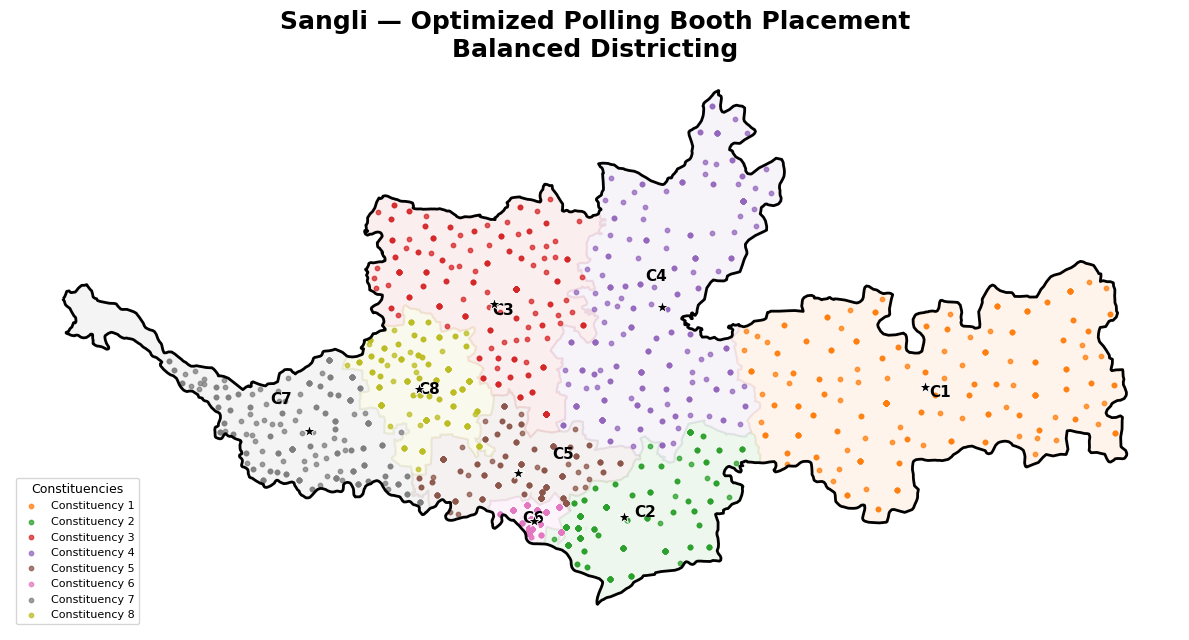

Saved: logistics_euclidean/FINAL_booth_map_balanced.png


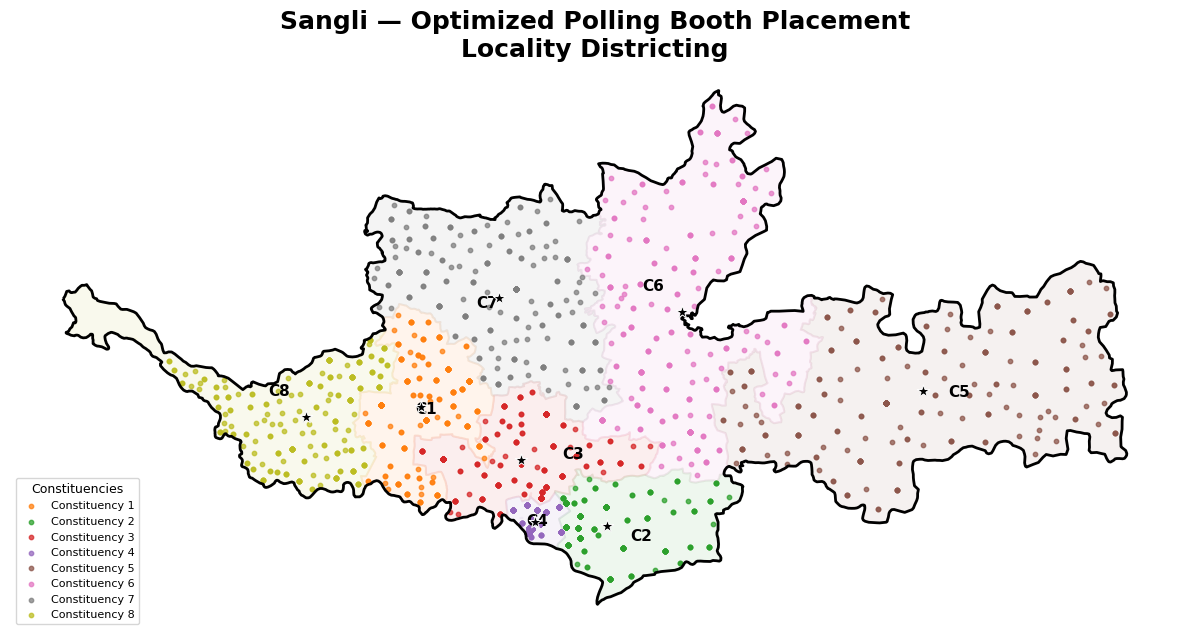

Saved: logistics_euclidean/FINAL_booth_map_locality.png


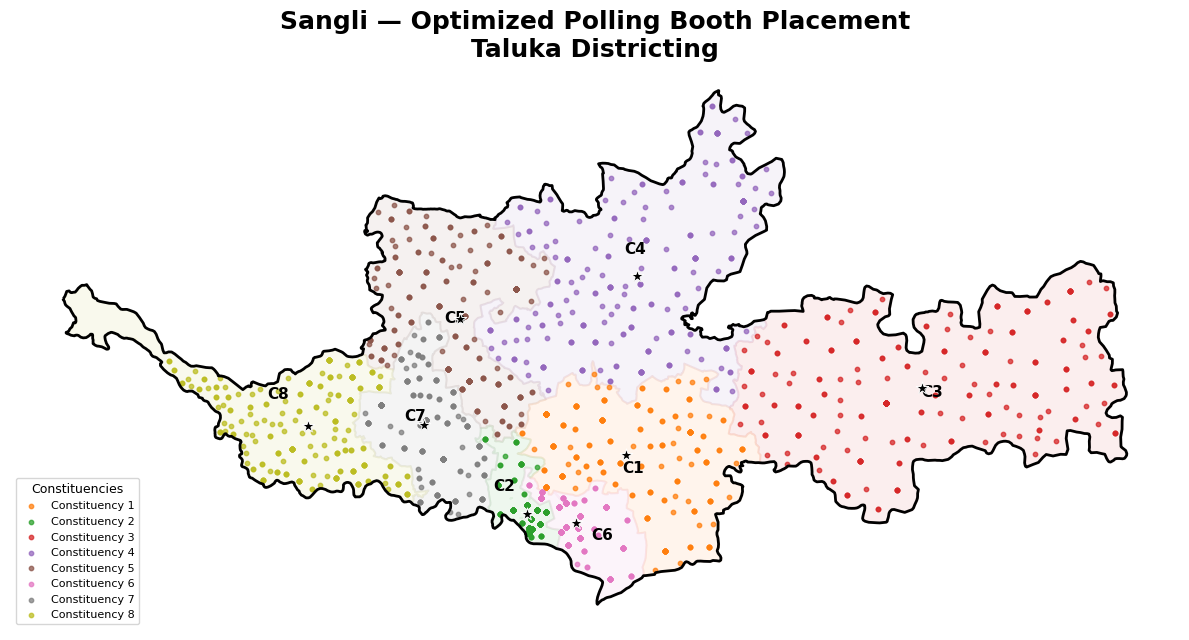

Saved: logistics_euclidean/FINAL_booth_map_taluka.png


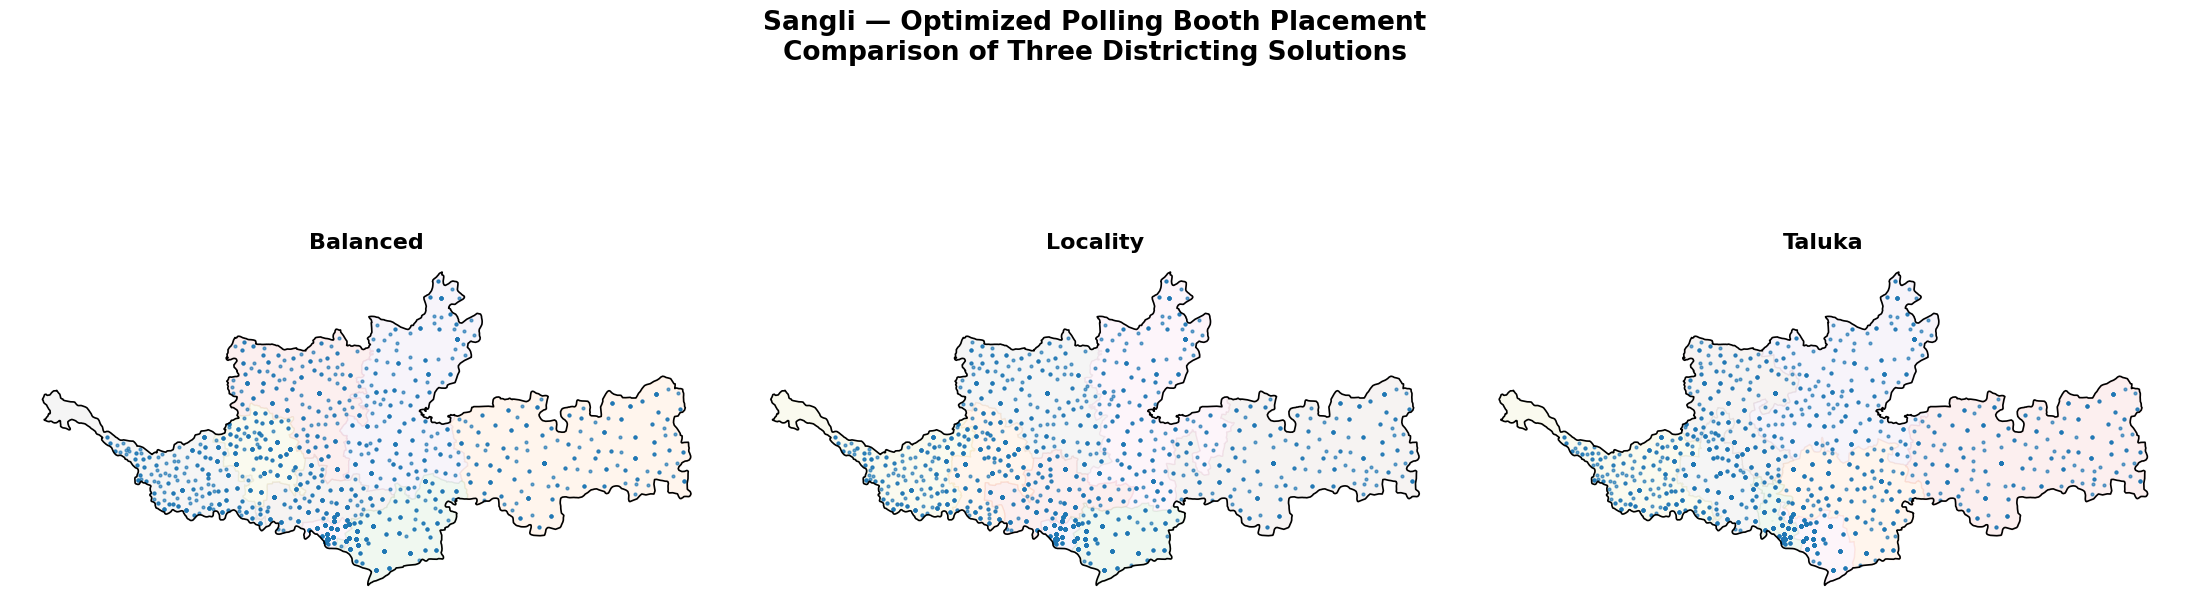


DONE
Final comparison image:
logistics_euclidean/FINAL_booth_map_comparison.png

Individual maps:
logistics_euclidean/FINAL_booth_map_balanced.png
logistics_euclidean/FINAL_booth_map_locality.png
logistics_euclidean/FINAL_booth_map_taluka.png


In [ ]:
# ================================================================
# FINAL PRESENTATION-READY BOOTH MAPS
# Run this AFTER the previous booth-placement code
# ================================================================

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from math import cos, radians

OUT = Path("logistics_euclidean")

# ------------------------------------------------
# Load district
# ------------------------------------------------

district = gpd.read_file(
    "sangli_input/sangli_district.geojson"
)

# District centre used in the previous model
district_centroid = district.geometry.iloc[0].centroid

LON0 = district_centroid.x
LAT0 = district_centroid.y


# ------------------------------------------------
# Convert the model's x-y km coordinates back
# into longitude/latitude for plotting
# ------------------------------------------------

def km_to_lonlat(x, y, lon0, lat0):

    lon = lon0 + x / (
        111.32 * cos(radians(lat0))
    )

    lat = lat0 + y / 110.57

    return lon, lat


# ------------------------------------------------
# Colours for the 8 constituencies
# ------------------------------------------------

cmap = plt.cm.tab10


# ------------------------------------------------
# Create one clean map for each solution
# ------------------------------------------------

for map_name in ["Balanced", "Locality", "Taluka"]:

    # Original spatial units
    units = gpd.read_file(
        f"map_{map_name.lower()}/assigned_units.geojson"
    )

    # Booths generated by our optimization
    booths = all_results[map_name]["booths"].copy()

    # ------------------------------------------------------------
    # Create constituency polygons by dissolving population units
    # ------------------------------------------------------------

    constituency_polygons = (
        units
        .dissolve(
            by="constituency",
            as_index=False
        )
    )

    # ------------------------------------------------------------
    # Convert booth x/y back to lon/lat
    # ------------------------------------------------------------

    booth_lon = []
    booth_lat = []

    for x, y in zip(
        booths["x"],
        booths["y"]
    ):

        lon, lat = km_to_lonlat(
            x,
            y,
            LON0,
            LAT0
        )

        booth_lon.append(lon)
        booth_lat.append(lat)

    booths["lon"] = booth_lon
    booths["lat"] = booth_lat

    # Convert booths into GeoDataFrame
    booth_gdf = gpd.GeoDataFrame(
        booths,
        geometry=gpd.points_from_xy(
            booths["lon"],
            booths["lat"]
        ),
        crs=units.crs
    )

    # ------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(12, 12)
    )

    # District outline
    district.boundary.plot(
        ax=ax,
        linewidth=2,
        color="black"
    )

    # ------------------------------------------------------------
    # Constituency colours + boundaries
    # ------------------------------------------------------------

    for idx, row in constituency_polygons.iterrows():

        colour = cmap(
            int(row["constituency"]) % 10
        )

        gpd.GeoSeries(
            [row.geometry],
            crs=units.crs
        ).plot(
            ax=ax,
            facecolor=colour,
            alpha=0.08,
            edgecolor=colour,
            linewidth=1.5
        )

        # Constituency number at representative point
        p = row.geometry.representative_point()

        ax.text(
            p.x,
            p.y,
            f"C{int(row['constituency'])}",
            fontsize=11,
            fontweight="bold",
            ha="center",
            va="center"
        )

    # ------------------------------------------------------------
    # Plot booths
    # ------------------------------------------------------------

    for constituency in sorted(
        booth_gdf["constituency"].unique()
    ):

        b = booth_gdf[
            booth_gdf["constituency"]
            == constituency
        ]

        colour = cmap(
            int(constituency) % 10
        )

        ax.scatter(
            b.geometry.x,
            b.geometry.y,
            s=10,
            color=colour,
            alpha=0.75,
            label=f"Constituency {int(constituency)}"
        )

    # ------------------------------------------------------------
    # Plot constituency warehouses
    # ------------------------------------------------------------

    for constituency in sorted(
        units["constituency"].unique()
    ):

        c = units[
            units["constituency"]
            == constituency
        ]

        # Population-weighted warehouse location
        lon = c["demand_lon"].to_numpy()
        lat = c["demand_lat"].to_numpy()
        pop = c["population"].to_numpy()

        warehouse_lon = np.average(
            lon,
            weights=pop
        )

        warehouse_lat = np.average(
            lat,
            weights=pop
        )

        ax.scatter(
            warehouse_lon,
            warehouse_lat,
            marker="*",
            s=90,
            color="black",
            edgecolor="white",
            linewidth=0.7,
            zorder=5
        )

    # ------------------------------------------------------------
    # Formatting
    # ------------------------------------------------------------

    ax.set_title(
        "Sangli — Optimized Polling Booth Placement\n"
        f"{map_name} Districting",
        fontsize=18,
        fontweight="bold"
    )

    ax.set_axis_off()

    # Only show one legend entry per constituency
    handles, labels = ax.get_legend_handles_labels()

    by_label = dict(zip(labels, handles))

    ax.legend(
        by_label.values(),
        by_label.keys(),
        title="Constituencies",
        loc="lower left",
        fontsize=8,
        title_fontsize=9
    )

    plt.tight_layout()

    filename = (
        OUT
        / f"FINAL_booth_map_{map_name.lower()}.png"
    )

    plt.savefig(
        filename,
        dpi=350,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(
        f"Saved: {filename}"
    )


# ================================================================
# THREE-MAP COMPARISON
# ================================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(22, 8)
)

for ax, map_name in zip(
    axes,
    ["Balanced", "Locality", "Taluka"]
):

    units = gpd.read_file(
        f"map_{map_name.lower()}/assigned_units.geojson"
    )

    booths = all_results[map_name]["booths"].copy()

    # Convert booths back to lon/lat
    coords = [
        km_to_lonlat(
            x,
            y,
            LON0,
            LAT0
        )
        for x, y in zip(
            booths["x"],
            booths["y"]
        )
    ]

    booths["lon"] = [
        p[0] for p in coords
    ]

    booths["lat"] = [
        p[1] for p in coords
    ]

    # Constituency boundaries
    constituency_polygons = (
        units
        .dissolve(
            by="constituency",
            as_index=False
        )
    )

    # District
    district.boundary.plot(
        ax=ax,
        linewidth=1.2,
        color="black"
    )

    # Constituencies
    for _, row in constituency_polygons.iterrows():

        colour = cmap(
            int(row["constituency"]) % 10
        )

        gpd.GeoSeries(
            [row.geometry],
            crs=units.crs
        ).plot(
            ax=ax,
            facecolor=colour,
            alpha=0.07,
            edgecolor=colour,
            linewidth=1
        )

    # Booths
    ax.scatter(
        booths["lon"],
        booths["lat"],
        s=4,
        alpha=0.65
    )

    ax.set_title(
        map_name,
        fontsize=16,
        fontweight="bold"
    )

    ax.set_axis_off()


fig.suptitle(
    "Sangli — Optimized Polling Booth Placement\n"
    "Comparison of Three Districting Solutions",
    fontsize=19,
    fontweight="bold"
)

plt.tight_layout()

comparison_file = (
    OUT / "FINAL_booth_map_comparison.png"
)

plt.savefig(
    comparison_file,
    dpi=350,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\n" + "=" * 60)
print("DONE")
print("=" * 60)
print(
    "Final comparison image:"
)
print(comparison_file)

print("\nIndividual maps:")
print(OUT / "FINAL_booth_map_balanced.png")
print(OUT / "FINAL_booth_map_locality.png")
print(OUT / "FINAL_booth_map_taluka.png")